# Modelo exponencial linearizável e coeficiente de determinação

Este exercício será desenvolvido como um caderno de leitura contínua: dados, linearização, cálculo manual, verificação em Python, retorno à curva exponencial e avaliação do ajuste.

## Questão principal: qual $R^2$ avalia a curva exponencial?

Existem dois cálculos relacionados, mas diferentes:

- $R^2_{\ln}$ avalia a **reta linearizada**, comparando $\ln(y_i)$ com $\widehat{\ln(y_i)}$;
- $R^2_{\mathrm{exp}}$ avalia a **curva na escala original**, comparando $y_i$ com $\widehat y_i=\alpha\beta^{x_i}$.

Como queremos avaliar a **curva exponencial**, o indicador principal será $R^2_{\mathrm{exp}}$. O $R^2_{\ln}$ também será calculado e identificado como medida da qualidade da linearização.

> A regressão é realizada na escala logarítmica. Assim, $R^2_{\mathrm{exp}}$ é uma avaliação posterior da curva na escala original; ele não é a quantidade minimizada durante o ajuste linearizado.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def tabela_com_somatorios(tabela, colunas_somar, casas=4):
    """Cria uma cópia apenas para exibição, com uma linha final de somatórios."""
    exibicao = tabela.round(casas).astype(object)
    linha_soma = {coluna: '' for coluna in exibicao.columns}

    for coluna in colunas_somar:
        linha_soma[coluna] = round(tabela[coluna].sum(), casas)

    exibicao.loc['Σ'] = linha_soma

    return exibicao

## 1. Dados do exercício

A variável `Ano` representa os anos de referência $1,3,5,\ldots,19$. O DataFrame abaixo será a tabela oficial do exercício; os dados não serão repetidos em Markdown.

In [2]:
ano_ref = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
inflacao = [9, 24, 72, 128, 192, 277, 373, 613, 1236, 2639]

df = pd.DataFrame({
    'Ano': ano_ref,
    'Inflação': inflacao
})

df

,Ano,Inflação
0,1,9
1,3,24
2,5,72
3,7,128
4,9,192
5,11,277
6,13,373
7,15,613
8,17,1236
9,19,2639


## 2. Linearização do modelo exponencial

O modelo exponencial é

$$
y=\alpha\beta^x.
$$

Aplicando o logaritmo natural:

$$
\begin{aligned}
\ln(y)&=\ln\left(\alpha\beta^x\right)\\
&=\ln(\alpha)+\ln\left(\beta^x\right)\\
&=\ln(\alpha)+x\ln(\beta).
\end{aligned}
$$

Definindo

$$
Y=\ln(y),\qquad A=\ln(\alpha),\qquad B=\ln(\beta),
$$

obtemos a reta

$$
Y=A+Bx.
$$

## 3. Preparação da tabela de cálculo

Para calcular $A$ e $B$ pelo método dos mínimos quadrados, acrescentamos $x_i^2$, $Y_i=\ln(y_i)$ e $x_iY_i$. Os logaritmos serão guardados com toda a precisão; o arredondamento será usado apenas na exibição.

A linha $\Sigma$ será acrescentada somente à tabela exibida. Ela não fará parte do `df` e, portanto, não interferirá nos cálculos posteriores.

In [3]:
df['Ano^2'] = df['Ano']**2
df['ln(inflação)'] = np.log(df['Inflação'])
df['xY'] = df['Ano'] * df['ln(inflação)']

display(
    tabela_com_somatorios(
        df[['Ano', 'Inflação', 'Ano^2', 'ln(inflação)', 'xY']],
        colunas_somar=[
            'Ano', 'Inflação', 'Ano^2', 'ln(inflação)', 'xY'
        ]
    )
)

,Ano,Inflação,Ano^2,ln(inflação),xY
0,1,9,1,2.1972,2.1972
1,3,24,9,3.1781,9.5342
2,5,72,25,4.2767,21.3833
3,7,128,49,4.852,33.9642
4,9,192,81,5.2575,47.3175
5,11,277,121,5.624,61.8642
6,13,373,169,5.9216,76.9805
7,15,613,225,6.4184,96.2755
8,17,1236,289,7.1196,121.0338
9,19,2639,361,7.8782,149.685


## 4. Cálculo manual e verificação com `np.polyfit`

O coeficiente angular é

$$
B=\frac{\displaystyle\sum_{i=1}^{n}x_iY_i-n\bar{x}\bar{Y}}
{\displaystyle\sum_{i=1}^{n}x_i^2-n\bar{x}^{2}}.
$$

Para estes dados:

$$
n=10,\quad \bar{x}=10,\quad \bar{Y}=5{,}272322,\quad
\sum x_iY_i=620{,}235330,\quad \sum x_i^2=1330.
$$

Então,

$$
B=\frac{620{,}235330-(10\cdot10\cdot5{,}272322)}
{1330-(10\cdot10^2)}=0{,}281828.
$$

O coeficiente linear é

$$
A=\bar{Y}-B\bar{x}
=5{,}272322-(0{,}281828\cdot10)=2{,}454046.
$$

In [4]:
n = len(df)
media_x = df['Ano'].mean()
media_Y = df['ln(inflação)'].mean()
soma_xY = df['xY'].sum()
soma_x2 = df['Ano^2'].sum()

# np.polyfit retorna primeiro o coeficiente angular e depois o linear
B, A = np.polyfit(
    df['Ano'],
    df['ln(inflação)'],
    1
)

print(f'n = {n}')
print(f'Média de x = {media_x:.6f}')
print(f'Média de Y = {media_Y:.6f}')
print(f'Somatório de xY = {soma_xY:.6f}')
print(f'Somatório de x² = {soma_x2:.6f}')
print(f'A retornado pelo np.polyfit = {A:.6f}')
print(f'B retornado pelo np.polyfit = {B:.6f}')

n = 10
Média de x = 10.000000
Média de Y = 5.272322
Somatório de xY = 620.235330
Somatório de x² = 1330.000000
A retornado pelo np.polyfit = 2.454046
B retornado pelo np.polyfit = 0.281828


A reta linearizada é

$$
\boxed{\widehat{\ln(y)}=2{,}454046+0{,}281828x}.
$$

O gráfico seguinte mostra os dados e a reta na mesma escala logarítmica.

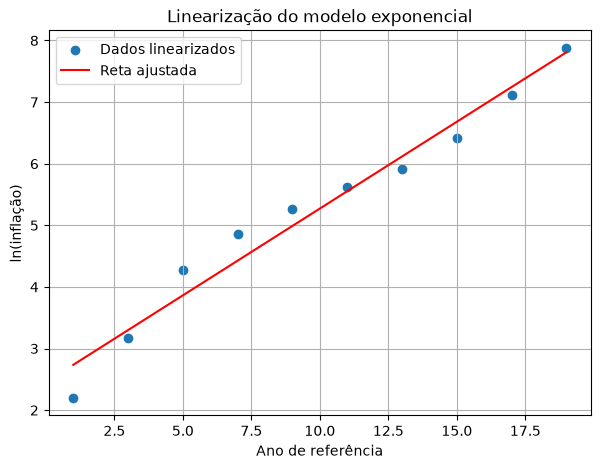

In [5]:
x_reta = np.linspace(df['Ano'].min(), df['Ano'].max(), 100)
ln_y_reta = A + B * x_reta

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df['Ano'], df['ln(inflação)'], label='Dados linearizados')
ax.plot(x_reta, ln_y_reta, color='red', label='Reta ajustada')
ax.set_title('Linearização do modelo exponencial')
ax.set_xlabel('Ano de referência')
ax.set_ylabel(r'$\ln(\mathrm{inflação})$')
ax.grid(True)
ax.legend()
plt.show()

## 5. Retorno à curva exponencial

Como $A=\ln(\alpha)$ e $B=\ln(\beta)$, então

$$
\alpha=e^A\qquad\text{e}\qquad\beta=e^B.
$$

In [6]:
alpha = np.exp(A)
beta = np.exp(B)
df['y_hat_exp'] = alpha * beta**df['Ano']

print(f'alpha = {alpha:.6f}')
print(f'beta = {beta:.6f}')
display(df[['Ano', 'Inflação', 'y_hat_exp']].round(4))

alpha = 11.635330
beta = 1.325550


,Ano,Inflação,y_hat_exp
0,1,9,15.4232
1,3,24,27.0999
2,5,72,47.6167
3,7,128,83.6666
4,9,192,147.0091
5,11,277,258.3073
6,13,373,453.8674
7,15,613,797.4828
8,17,1236,1401.2437
9,19,2639,2462.1018


Portanto, a curva ajustada na escala original é

$$
\boxed{\widehat y=11{,}635330(1{,}325550)^x}.
$$

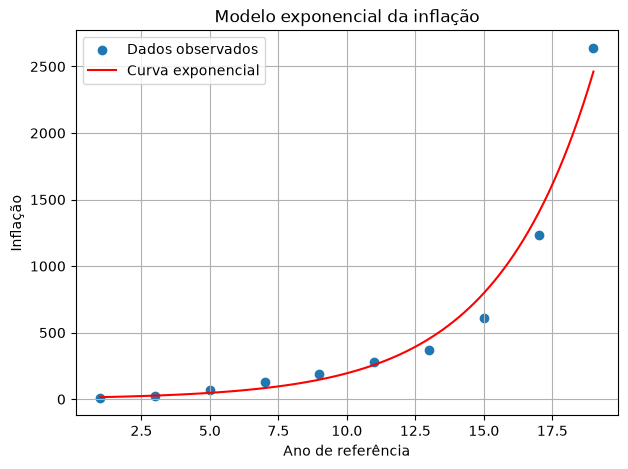

In [7]:
y_exponencial = alpha * beta**x_reta

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df['Ano'], df['Inflação'], label='Dados observados')
ax.plot(x_reta, y_exponencial, color='red', label='Curva exponencial')
ax.set_title('Modelo exponencial da inflação')
ax.set_xlabel('Ano de referência')
ax.set_ylabel('Inflação')
ax.grid(True)
ax.legend()
plt.show()

## 6. $R^2$ da curva exponencial — cálculo principal

Agora os erros são calculados nas unidades originais da inflação, usando

$$
\widehat y_i=\alpha\beta^{x_i}.
$$

O coeficiente de determinação da curva é

$$
R^2_{\mathrm{exp}}
=1-\frac{\displaystyle\sum_{i=1}^{n}(y_i-\widehat y_i)^2}
{\displaystyle\sum_{i=1}^{n}(y_i-\bar y)^2}.
$$

O numerador mede o erro deixado pela curva. O denominador mede a variação total dos valores originais em torno da média.

In [8]:
df['Residuo_exp'] = df['Inflação'] - df['y_hat_exp']
df['Residuo_exp^2'] = df['Residuo_exp']**2
media_y = df['Inflação'].mean()
df['Desvio_total_exp^2'] = (df['Inflação'] - media_y)**2

display(
    tabela_com_somatorios(
        df[[
            'Ano', 'Inflação', 'y_hat_exp', 'Residuo_exp',
            'Residuo_exp^2', 'Desvio_total_exp^2'
        ]],
        colunas_somar=[
            'Residuo_exp^2', 'Desvio_total_exp^2'
        ]
    )
)

,Ano,Inflação,y_hat_exp,Residuo_exp,Residuo_exp^2,Desvio_total_exp^2
0,1,9,15.4232,-6.4232,41.2577,299537.29
1,3,24,27.0999,-3.0999,9.6092,283343.29
2,5,72,47.6167,24.3833,594.5439,234546.49
3,7,128,83.6666,44.3334,1965.4539,183440.89
4,9,192,147.0091,44.9909,2024.1797,132714.49
5,11,277,258.3073,18.6927,349.4185,78008.49
6,13,373,453.8674,-80.8674,6539.5316,33598.89
7,15,613,797.4828,-184.4828,34033.8934,3214.89
8,17,1236,1401.2437,-165.2437,27305.4654,461992.09
9,19,2639,2462.1018,176.8982,31292.969,4337639.29


In [9]:
SQ_residuo_exp = df['Residuo_exp^2'].sum()
SQ_total_exp = df['Desvio_total_exp^2'].sum()
R2_exp = 1 - SQ_residuo_exp / SQ_total_exp

print(f'SQ dos resíduos da curva = {SQ_residuo_exp:.6f}')
print(f'SQ total na escala original = {SQ_total_exp:.6f}')
print(f'R² da curva exponencial = {R2_exp:.6f}')
print(f'R² da curva exponencial = {R2_exp:.2%}')

SQ dos resíduos da curva = 104156.322263
SQ total na escala original = 6048036.100000
R² da curva exponencial = 0.982778
R² da curva exponencial = 98.28%


O resultado é

$$
\boxed{R^2_{\mathrm{exp}}=0{,}9828\approx98{,}28\%}.
$$

Na escala original, a curva exponencial acompanha grande parte da variação observada na inflação.

## 7. $R^2$ da reta linearizada — cálculo complementar

Agora avaliamos a regressão na escala em que ela foi ajustada:

$$
R^2_{\ln}=1-\frac{\displaystyle\sum_{i=1}^{n}\left[\ln(y_i)-\widehat{\ln(y_i)}\right]^2}
{\displaystyle\sum_{i=1}^{n}\left[\ln(y_i)-\overline{\ln(y)}\right]^2}.
$$

Aqui, os erros são medidos em $\ln(y)$, e não nas unidades originais da inflação.

In [10]:
df['ln_y_hat'] = A + B * df['Ano']
df['Residuo_ln'] = df['ln(inflação)'] - df['ln_y_hat']
df['Residuo_ln^2'] = df['Residuo_ln']**2
df['Desvio_total_ln^2'] = (df['ln(inflação)'] - media_Y)**2

display(
    tabela_com_somatorios(
        df[[
            'Ano', 'ln(inflação)', 'ln_y_hat', 'Residuo_ln',
            'Residuo_ln^2', 'Desvio_total_ln^2'
        ]],
        colunas_somar=[
            'Residuo_ln^2', 'Desvio_total_ln^2'
        ]
    )
)

,Ano,ln(inflação),ln_y_hat,Residuo_ln,Residuo_ln^2,Desvio_total_ln^2
0,1,2.1972,2.7359,-0.5386,0.2901,9.4562
1,3,3.1781,3.2995,-0.1215,0.0148,4.386
2,5,4.2767,3.8632,0.4135,0.171,0.9913
3,7,4.852,4.4268,0.4252,0.1808,0.1766
4,9,5.2575,4.9905,0.267,0.0713,0.0002
5,11,5.624,5.5541,0.0699,0.0049,0.1237
6,13,5.9216,6.1178,-0.1962,0.0385,0.4215
7,15,6.4184,6.6815,-0.2631,0.0692,1.3134
8,17,7.1196,7.2451,-0.1255,0.0157,3.4126
9,19,7.8782,7.8088,0.0694,0.0048,6.7904


In [11]:
SQ_residuo_ln = df['Residuo_ln^2'].sum()
SQ_total_ln = df['Desvio_total_ln^2'].sum()
R2_ln = 1 - SQ_residuo_ln / SQ_total_ln

print(f'SQ dos resíduos linearizados = {SQ_residuo_ln:.6f}')
print(f'SQ total na escala logarítmica = {SQ_total_ln:.6f}')
print(f'R² da reta linearizada = {R2_ln:.6f}')
print(f'R² da reta linearizada = {R2_ln:.2%}')

SQ dos resíduos linearizados = 0.861108
SQ total na escala logarítmica = 27.071952
R² da reta linearizada = 0.968192
R² da reta linearizada = 96.82%


O resultado complementar é

$$
\boxed{R^2_{\ln}=0{,}9682\approx96{,}82\%}.
$$

Isso informa que a relação entre `Ano` e $\ln(\mathrm{Inflação})$ é fortemente linear.

## 8. Resíduos da curva exponencial

No gráfico de resíduos, o eixo vertical contém $y_i-\widehat y_i$. Por isso, a referência correta é uma linha horizontal em zero, e não a própria curva exponencial.

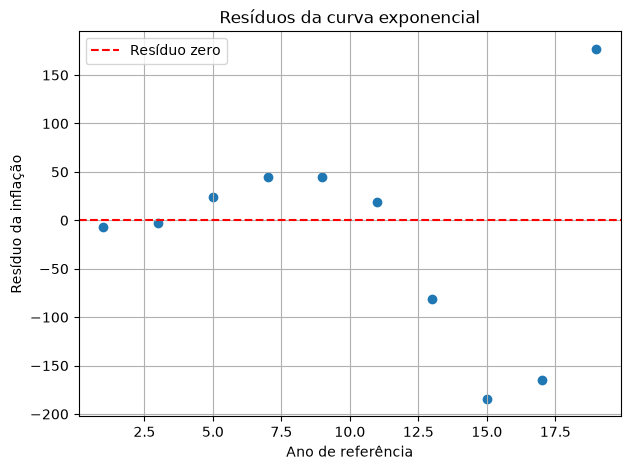

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df['Ano'], df['Residuo_exp'])
ax.axhline(y=0, color='red', linestyle='--', label='Resíduo zero')
ax.set_title('Resíduos da curva exponencial')
ax.set_xlabel('Ano de referência')
ax.set_ylabel('Resíduo da inflação')
ax.grid(True)
ax.legend()
plt.show()

## 9. Resumo numérico dos resultados

Reunimos abaixo os coeficientes e os dois valores de $R^2$ para consulta, sem substituir as tabelas e contas anteriores.

In [13]:
print(f'A = {A:.10f}')
print(f'B = {B:.10f}')
print(f'alpha = {alpha:.10f}')
print(f'beta = {beta:.10f}')
print(f'R² da curva exponencial = {R2_exp:.6f}')
print(f'R² da reta linearizada = {R2_ln:.6f}')

A = 2.4540461341
B = 0.2818276066
alpha = 11.6353297094
beta = 1.3255501842
R² da curva exponencial = 0.982778
R² da reta linearizada = 0.968192


## 10. Conclusão

A regressão linearizada forneceu

$$
\widehat{\ln(y)}=2{,}454046+0{,}281828x.
$$

Na escala original, obtivemos

$$
\widehat y=11{,}635330(1{,}325550)^x.
$$

Os dois coeficientes de determinação foram

$$
R^2_{\mathrm{exp}}\approx98{,}28\%\qquad\text{e}\qquad
R^2_{\ln}\approx96{,}82\%.
$$

O primeiro avalia a **curva exponencial nas unidades originais da inflação** e responde à questão principal. O segundo avalia a **reta usada na linearização**. Eles não devem ser confundidos como se fossem calculados na mesma escala.